Installing Libraries

In [ ]:
!pip install wfdb PyWavelets scikit-learn scipy pandas matplotlib seaborn

Importing Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import pywt
from scipy import signal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

Clean ECG data - Record 118


In [ ]:
!rm -f /content/118.dat /content/118.hea
!wget -q -O /content/118.dat https://physionet.org/files/mitdb/1.0.0/118.dat
!wget -q -O /content/118.hea https://physionet.org/files/mitdb/1.0.0/118.hea

Noise Data - Baseline Wander, EM/Muscle noise & Motion Artifact

In [ ]:
!rm -f /content/bw.dat /content/bw.hea
!rm -f /content/em.dat /content/em.hea
!rm -f /content/ma.dat /content/ma.hea
!wget -q -O /content/bw.dat https://physionet.org/files/nstdb/1.0.0/bw.dat
!wget -q -O /content/bw.hea https://physionet.org/files/nstdb/1.0.0/bw.hea
!wget -q -O /content/em.dat https://physionet.org/files/nstdb/1.0.0/em.dat
!wget -q -O /content/em.hea https://physionet.org/files/nstdb/1.0.0/em.hea
!wget -q -O /content/ma.dat https://physionet.org/files/nstdb/1.0.0/ma.dat
!wget -q -O /content/ma.hea https://physionet.org/files/nstdb/1.0.0/ma.hea

Checking Downloaded Files

In [ ]:
!ls -lh *.dat *.hea

-rw-r--r-- 1 root root 1.9M Nov 29  2023 118.dat
-rw-r--r-- 1 root root  167 Nov 29  2023 118.hea
-rw-r--r-- 1 root root 1.9M Aug  2  1992 bw.dat
-rw-r--r-- 1 root root   93 Feb 14  2012 bw.hea
-rw-r--r-- 1 root root 1.9M Aug  2  1992 em.dat
-rw-r--r-- 1 root root   92 Feb 14  2012 em.hea
-rw-r--r-- 1 root root 1.9M Aug  2  1992 ma.dat
-rw-r--r-- 1 root root   90 Feb 14  2012 ma.hea


Loading and Visualizing Data

Load Clean ECG Record 118

In [ ]:
record_118 = wfdb.rdrecord('/content/118')
print("Sampling frequency:", record_118.fs)
print("Number of samples:", record_118.p_signal.shape[0])
print("Number of channels:", record_118.p_signal.shape[1])

Sampling frequency: 360
Number of samples: 650000
Number of channels: 2


In [ ]:
ecg_118 = record_118.p_signal[:, 0]
fs = record_118.fs
print("ECG length:", len(ecg_118))
print("Sampling frequency:", fs, "Hz")

ECG length: 650000
Sampling frequency: 360 Hz


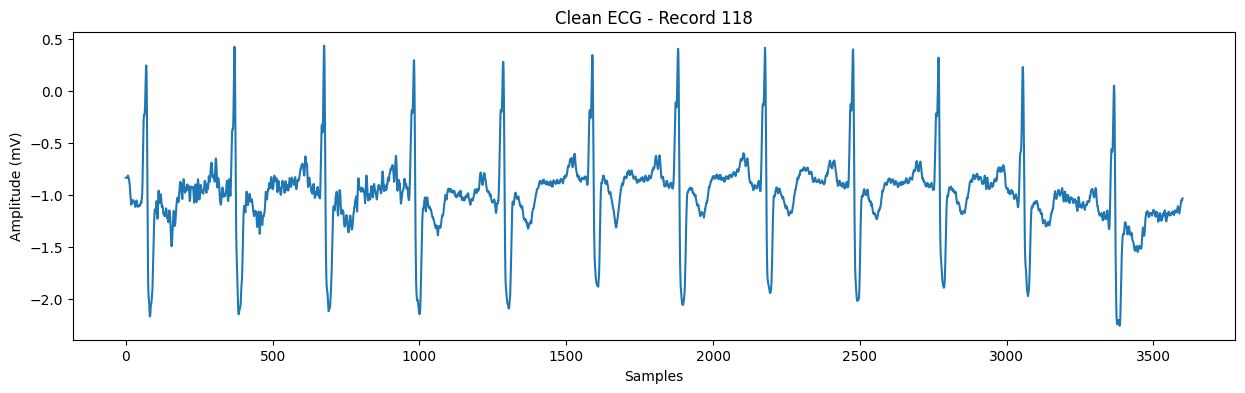

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(ecg_118[:3600])
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")
plt.title("Clean ECG - Record 118")

plt.show()

Load Noise Data - Baseline Wander, EM/Muscle noise & Motion Artifact

In [ ]:
bw_record = wfdb.rdrecord('/content/bw')
bw = bw_record.p_signal[:, 0]
print("Baseline Wander samples:", len(bw))
print("Sampling frequency:", bw_record.fs)
print("Number of channels:", bw_record.p_signal.shape[1])


ma_record = wfdb.rdrecord('/content/ma')
ma = ma_record.p_signal[:, 0]
print("Muscle / EMG Artifact samples:", len(ma))
print("Sampling frequency:", ma_record.fs)
print("Number of channels:", ma_record.p_signal.shape[1])


em_record = wfdb.rdrecord('/content/em')
em = em_record.p_signal[:, 0]
print("Electrode Motion Artifact samples:", len(em))
print("Sampling frequency:", em_record.fs)
print("Number of channels:", em_record.p_signal.shape[1])

Baseline Wander samples: 650000
Sampling frequency: 360
Number of channels: 2
Muscle / EMG Artifact samples: 650000
Sampling frequency: 360
Number of channels: 2
Electrode Motion Artifact samples: 650000
Sampling frequency: 360
Number of channels: 2


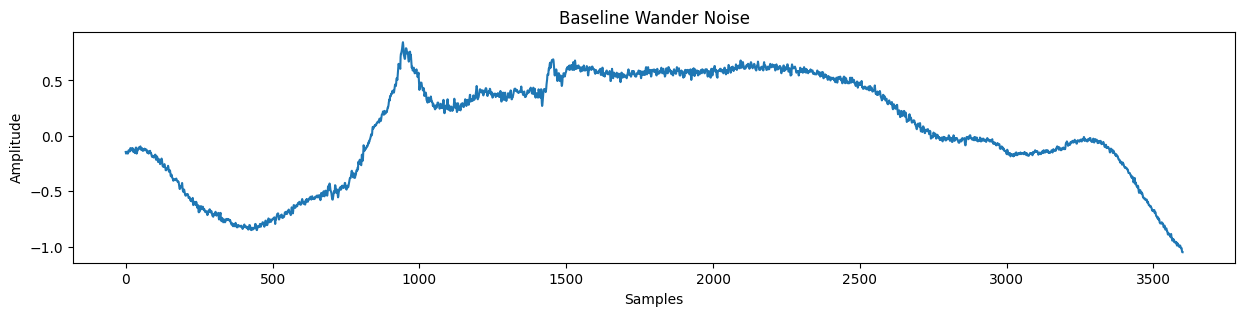

In [ ]:
plt.figure(figsize=(15, 3))
plt.plot(bw[:3600])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Baseline Wander Noise")
plt.show()

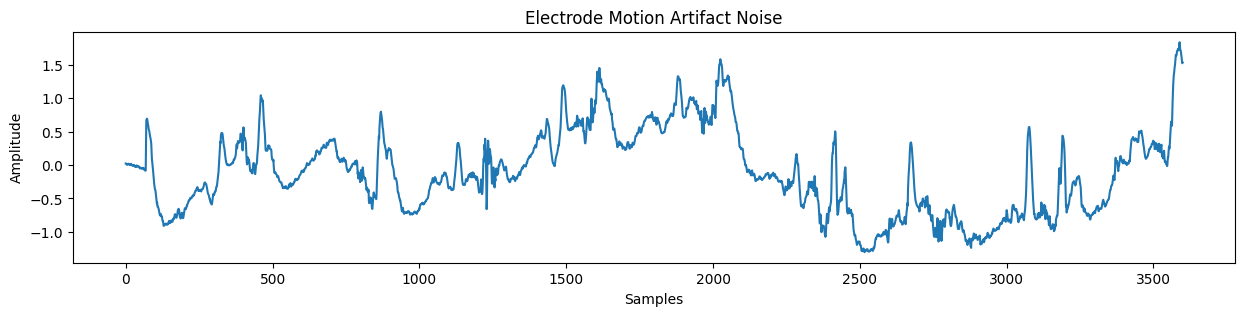

In [ ]:
plt.figure(figsize=(15, 3))
plt.plot(em[:3600])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Electrode Motion Artifact Noise")
plt.show()

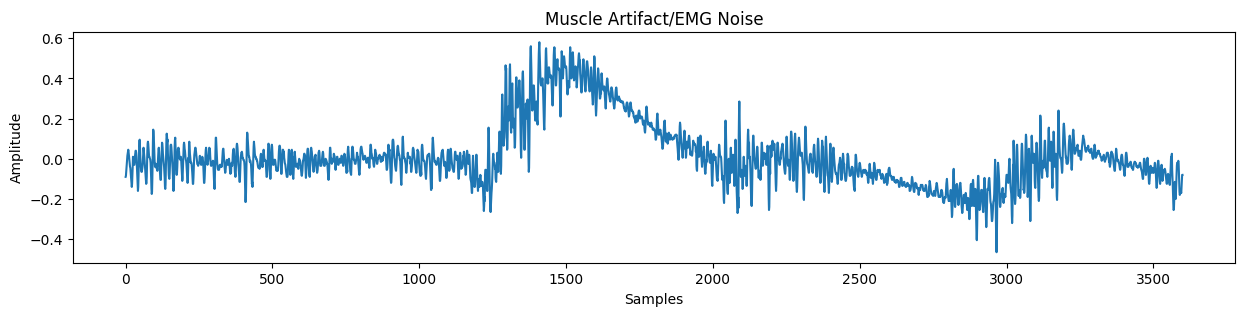

In [ ]:
plt.figure(figsize=(15, 3))
plt.plot(ma[:3600])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("Muscle Artifact/EMG Noise")
plt.show()

Preprocessing ECG and Noise Signals

In [ ]:
def preprocess_signal(signal_data):
    signal_data = np.asarray(signal_data, dtype=float)
    signal_data = signal_data - np.mean(signal_data)
    std = np.std(signal_data)
    if std != 0:
        signal_data = signal_data / std
    return signal_data

In [ ]:
ecg_118_processed = preprocess_signal(ecg_118)
bw_processed = preprocess_signal(bw)
ma_processed = preprocess_signal(ma)
em_processed = preprocess_signal(em)

In [ ]:
print("ECG mean:", np.mean(ecg_118_processed))
print("ECG standard deviation:", np.std(ecg_118_processed))
print("BW mean:", np.mean(bw_processed))
print("BW standard deviation:", np.std(bw_processed))
print("MA mean:", np.mean(ma_processed))
print("MA standard deviation:", np.std(ma_processed))
print("EM mean:", np.mean(em_processed))
print("EM standard deviation:", np.std(em_processed))

ECG mean: -6.812465121933761e-16
ECG standard deviation: 1.0
BW mean: -7.695724399617086e-18
BW standard deviation: 1.0000000000000002
MA mean: 1.8452248276354602e-17
MA standard deviation: 0.9999999999999999
EM mean: -1.1281232358529591e-17
EM standard deviation: 0.9999999999999997


In [ ]:
# Processed Signal Length
print("Processed ECG Length: ",len(ecg_118_processed))
print("Processed BW Length: ",len(bw_processed))
print("Processed MA Length: ",len(ma_processed))
print("Processed EM Length: ",len(em_processed))

Processed ECG Length:  650000
Processed BW Length:  650000
Processed MA Length:  650000
Processed EM Length:  650000


ECG Signal Segmentation

In [ ]:
fs = int(record_118.fs)
segment_duration = 5  # seconds
segment_length = fs * segment_duration
print("Sampling frequency:", fs)
print("Segment duration:", segment_duration, "seconds")
print("Samples per segment:", segment_length)

Sampling frequency: 360
Segment duration: 5 seconds
Samples per segment: 1800


In [ ]:
def create_segments(signal_data, segment_length):
    segments = []
    number_of_segments = len(signal_data) // segment_length
    for i in range(number_of_segments):
        start = i * segment_length
        end = start + segment_length
        segment = signal_data[start:end]
        segments.append(segment)
    return np.array(segments)

In [ ]:
ecg_segments = create_segments(ecg_118_processed, segment_length)
bw_segments = create_segments(bw_processed, segment_length)
ma_segments = create_segments(ma_processed, segment_length)
em_segments = create_segments(em_processed, segment_length)

In [ ]:
print("ECG segments:", ecg_segments.shape)
print("BW segments:", bw_segments.shape)
print("MA segments:", ma_segments.shape)
print("EM segments:", em_segments.shape)

ECG segments: (361, 1800)
BW segments: (361, 1800)
MA segments: (361, 1800)
EM segments: (361, 1800)


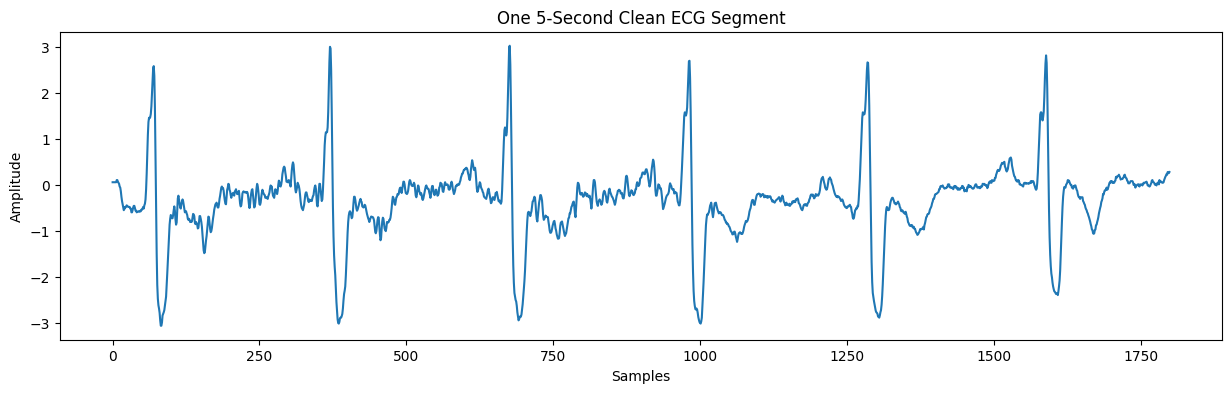

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(ecg_segments[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Clean ECG Segment")
plt.show()

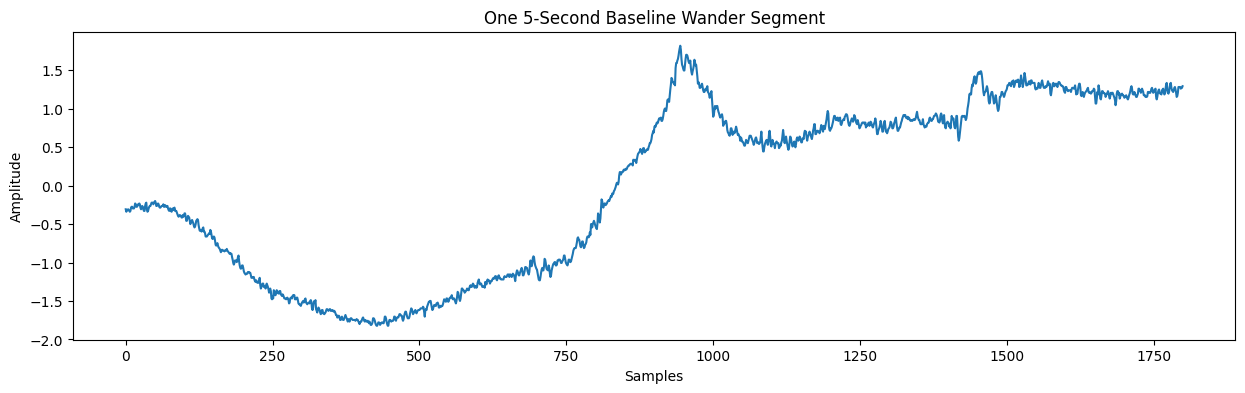

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(bw_segments[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Baseline Wander Segment")
plt.show()

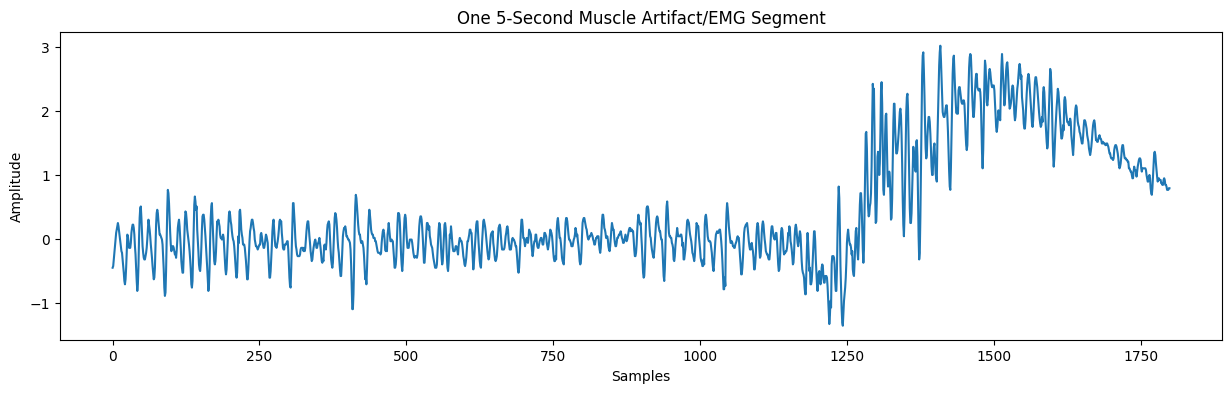

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(ma_segments[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Muscle Artifact/EMG Segment")
plt.show()

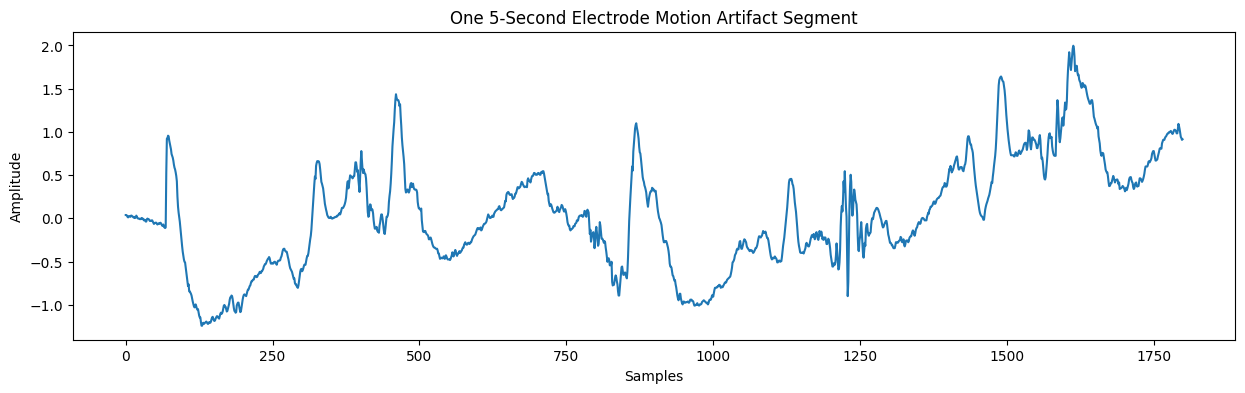

In [ ]:
plt.figure(figsize=(15, 4))
plt.plot(em_segments[0])
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.title("One 5-Second Electrode Motion Artifact Segment")
plt.show()

SNR-Based Noise Function

In [ ]:
def add_noise_snr(clean_signal, noise_signal, snr_db):
    noise_signal = noise_signal[:len(clean_signal)]
    noise_signal = noise_signal - np.mean(noise_signal)
    signal_power = np.mean(clean_signal ** 2)
    noise_power = np.mean(noise_signal ** 2)
    desired_noise_power = signal_power / (10 ** (snr_db / 10))
    noise_scale = np.sqrt(desired_noise_power / noise_power)
    scaled_noise = noise_scale * noise_signal
    noisy_signal = clean_signal + scaled_noise
    return noisy_signal

Creating Four-Class Dataset

In [ ]:
X_signals = []
y = []
num_segments = min(len(ecg_segments), len(bw_segments), len(ma_segments),
                   len(em_segments))
snr_db = 6
for i in range(num_segments):
    clean = ecg_segments[i]
    X_signals.append(clean)
    y.append(0)
    noisy_bw = add_noise_snr(clean, bw_segments[i], snr_db)
    X_signals.append(noisy_bw)
    y.append(1)
    noisy_ma = add_noise_snr(clean, ma_segments[i], snr_db)
    X_signals.append(noisy_ma)
    y.append(2)
    noisy_em = add_noise_snr(clean, em_segments[i], snr_db)
    X_signals.append(noisy_em)
    y.append(3)
X_signals = np.array(X_signals)
y = np.array(y)
print("X shape:", X_signals.shape)
print("y shape:", y.shape)
print("\nClass distribution:")
for class_number in range(4):
    print(f"Class {class_number}:", np.sum(y == class_number))

X shape: (1444, 1800)
y shape: (1444,)

Class distribution:
Class 0: 361
Class 1: 361
Class 2: 361
Class 3: 361


In [ ]:
def calculate_snr(clean_signal, noisy_signal):
    noise = noisy_signal - clean_signal
    signal_power = np.mean(clean_signal ** 2)
    noise_power = np.mean(noise ** 2)
    snr = 10 * np.log10(signal_power / noise_power)
    return snr

clean_test = ecg_segments[0]
noisy_test = add_noise_snr(clean_test, bw_segments[0], 6)
print("Actual SNR:", calculate_snr(clean_test, noisy_test), "dB")

Actual SNR: 6.000000000000001 dB


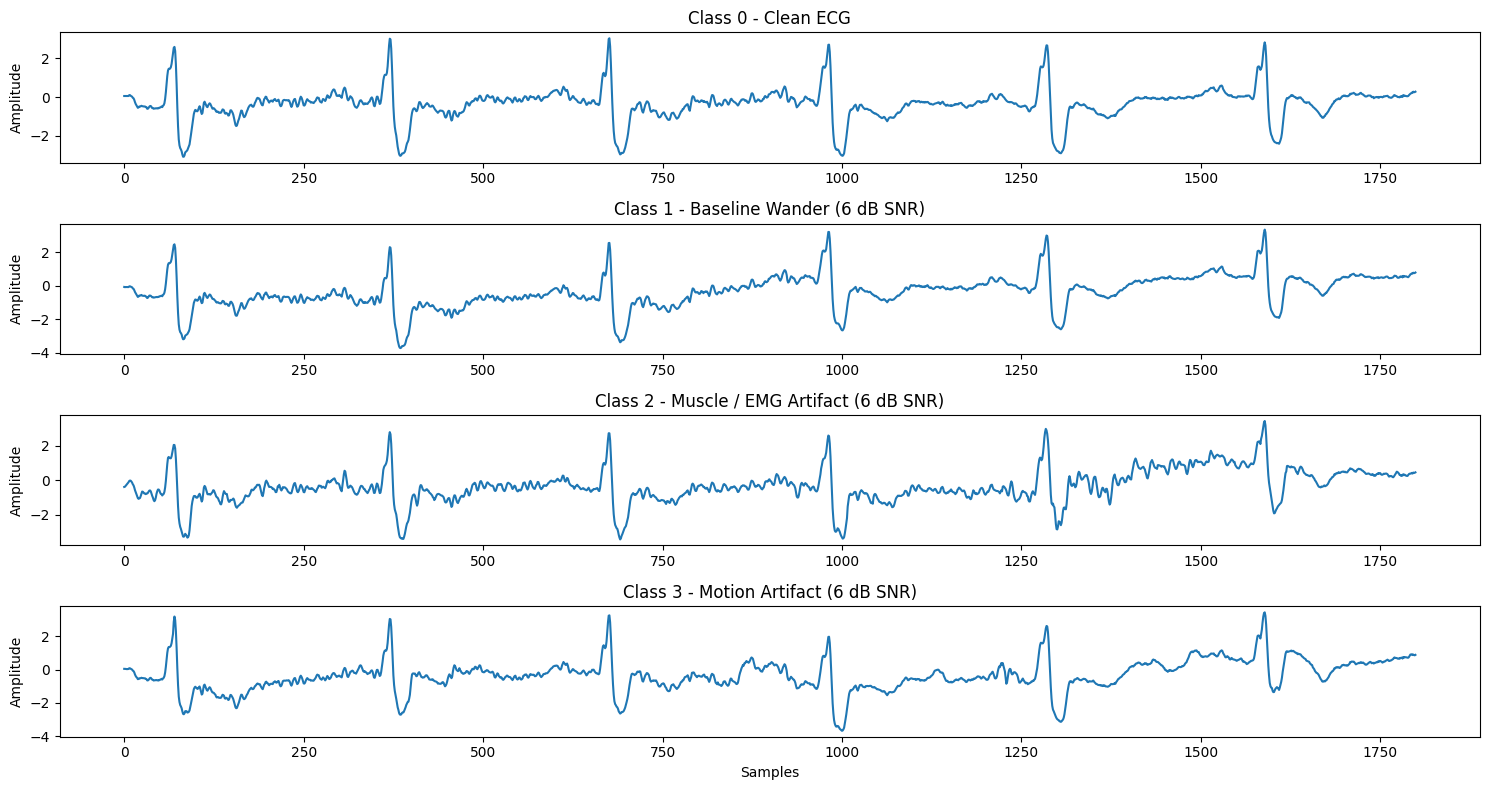

In [ ]:
plt.figure(figsize=(15, 8))
plt.subplot(4, 1, 1)
plt.plot(X_signals[0])
plt.title("Class 0 - Clean ECG")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 2)
plt.plot(X_signals[1])
plt.title("Class 1 - Baseline Wander (6 dB SNR)")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 3)
plt.plot(X_signals[2])
plt.title("Class 2 - Muscle / EMG Artifact (6 dB SNR)")
plt.ylabel("Amplitude")
plt.subplot(4, 1, 4)
plt.plot(X_signals[3])
plt.title("Class 3 - Motion Artifact (6 dB SNR)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

Creating Group IDs

In [ ]:
#    Each original ECG segment has 4 versions:
#    0 = Clean
#    1 = Baseline Wander
#    2 = Muscle/EMG
#    3 = Motion Artifact
group_ids = np.repeat(np.arange(num_segments), 4)
print("Group IDs shape:", group_ids.shape)
print("Number of groups:", len(np.unique(group_ids)))

Group IDs shape: (1444,)
Number of groups: 361


Training & Testing Data

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X_signals, y, groups=group_ids))
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

Training samples: 1152
Testing samples: 292


X_train, X_test, y_train, y_test

In [ ]:
X_train = X_signals[train_idx]
X_test = X_signals[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1152, 1800)
X_test shape: (292, 1800)
y_train shape: (1152,)
y_test shape: (292,)


Checking Classes

In [ ]:
print("Training class distribution:")
unique, counts = np.unique(y_train, return_counts=True)
for label, count in zip(unique, counts):
    print(f"Class {label}: {count}")
print("\nTesting class distribution:")
unique, counts = np.unique(y_test, return_counts=True)
for label, count in zip(unique, counts):
    print(f"Class {label}: {count}")

Training class distribution:
Class 0: 288
Class 1: 288
Class 2: 288
Class 3: 288

Testing class distribution:
Class 0: 73
Class 1: 73
Class 2: 73
Class 3: 73


Saving Train-Test Split Indices

In [ ]:
np.save("/content/train_idx.npy", train_idx)
np.save("/content/test_idx.npy", test_idx)
print("Train and test indices saved successfully.")

Train and test indices saved successfully.


Define DWT Feature Extraction

In [ ]:
import pywt
import numpy as np
from scipy.stats import skew, kurtosis

def dwt_features(x, wavelet="db4", level=8):
    # Apply DWT
    coeffs = pywt.wavedec(x, wavelet, level=level)
    features = []
    # Extract statistical features
    for c in coeffs:
        features.append(np.mean(c))               # Mean
        features.append(np.std(c))                # Standard Deviation
        features.append(np.var(c))                # Variance
        features.append(np.sqrt(np.mean(c**2)))   # RMS
        features.append(np.sum(c**2))             # Energy
        features.append(np.median(c))             # Median
        features.append(np.min(c))                # Minimum
        features.append(np.max(c))                # Maximum
        features.append(np.mean(np.abs(c)))       # Mean Absolute Value
        features.append(skew(c))                  # Skewness
        features.append(kurtosis(c))              # Kurtosis
        energy = c**2
        energy = energy / (np.sum(energy) + 1e-12)
        entropy = -np.sum(energy * np.log2(energy + 1e-12))
        features.append(entropy)
    return np.array(features)

Extracting DWT Features

In [ ]:
X_train_dwt = np.array([dwt_features(signal) for signal in X_train])
X_test_dwt = np.array([dwt_features(signal) for signal in X_test])
print("DWT training feature shape:", X_train_dwt.shape)
print("DWT testing feature shape:", X_test_dwt.shape)

DWT training feature shape: (1152, 108)
DWT testing feature shape: (292, 108)


Verifying DWT Features

In [ ]:
print("NaN values in training:", np.isnan(X_train_dwt).sum())
print("NaN values in testing:", np.isnan(X_test_dwt).sum())
print("Infinite values in training:", np.isinf(X_train_dwt).sum())
print("Infinite values in testing:", np.isinf(X_test_dwt).sum())

NaN values in training: 0
NaN values in testing: 0
Infinite values in training: 0
Infinite values in testing: 0


## Machine Learning Model Training

Decision Tree Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
# Train the model using DWT features
dt_model.fit(X_train_dwt, y_train)
print("Decision Tree training completed.")

Decision Tree training completed.


Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
# Create Random Forest model
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
# Train the model using DWT features
rf_model.fit(X_train_dwt, y_train)
print("Random Forest training completed.")

Random Forest training completed.


Support Vector Machine (SVM)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
# Create SVM model with feature scaling
svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
# Train the model using DWT features
svm_model.fit(X_train_dwt, y_train)
print("SVM training completed.")

SVM training completed.


## Model Testing and Evaluation

Class Names

In [ ]:
class_names = ["Clean ECG", "Baseline Wander", "EMG Artifact",
    "Motion Artifact"]

Decision Tree Evaluation

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, classification_report)
# Predict the classes of the test data
y_pred_dt = dt_model.predict(X_test_dwt)
# Calculate evaluation metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, average="weighted")
recall_dt = recall_score(y_test, y_pred_dt, average="weighted")
f1_dt = f1_score(y_test, y_pred_dt, average="weighted")
print("Decision Tree - DWT")
print("-------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1-score :", f1_dt)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=class_names))

Decision Tree - DWT
-------------------
Accuracy : 0.702054794520548
Precision: 0.708278042712005
Recall   : 0.702054794520548
F1-score : 0.6982789326110276

Classification Report:
                 precision    recall  f1-score   support

      Clean ECG       0.73      0.78      0.75        73
Baseline Wander       0.63      0.60      0.62        73
   EMG Artifact       0.68      0.85      0.76        73
Motion Artifact       0.79      0.58      0.67        73

       accuracy                           0.70       292
      macro avg       0.71      0.70      0.70       292
   weighted avg       0.71      0.70      0.70       292



Random Forest Evaluation

In [ ]:
y_pred_rf = rf_model.predict(X_test_dwt)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average="weighted")
recall_rf = recall_score(y_test, y_pred_rf, average="weighted")
f1_rf = f1_score(y_test, y_pred_rf, average="weighted")
print("Random Forest - DWT")
print("-------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1-score :", f1_rf)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=class_names))

Random Forest - DWT
-------------------
Accuracy : 0.7773972602739726
Precision: 0.7787885843747154
Recall   : 0.7773972602739726
F1-score : 0.7769157167503568

Classification Report:
                 precision    recall  f1-score   support

      Clean ECG       0.85      0.77      0.81        73
Baseline Wander       0.72      0.68      0.70        73
   EMG Artifact       0.82      0.88      0.85        73
Motion Artifact       0.72      0.78      0.75        73

       accuracy                           0.78       292
      macro avg       0.78      0.78      0.78       292
   weighted avg       0.78      0.78      0.78       292



Support Vector Machine Evaluation

In [ ]:
y_pred_svm = svm_model.predict(X_test_dwt)
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average="weighted")
recall_svm = recall_score(y_test, y_pred_svm, average="weighted")
f1_svm = f1_score(y_test, y_pred_svm, average="weighted")
print("SVM - DWT")
print("---------")
print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1-score :", f1_svm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, target_names=class_names))

SVM - DWT
---------
Accuracy : 0.726027397260274
Precision: 0.7219804827836177
Recall   : 0.726027397260274
F1-score : 0.7222760758843528

Classification Report:
                 precision    recall  f1-score   support

      Clean ECG       0.69      0.77      0.73        73
Baseline Wander       0.62      0.52      0.57        73
   EMG Artifact       0.80      0.81      0.80        73
Motion Artifact       0.78      0.81      0.79        73

       accuracy                           0.73       292
      macro avg       0.72      0.73      0.72       292
   weighted avg       0.72      0.73      0.72       292



Confusion Matrices

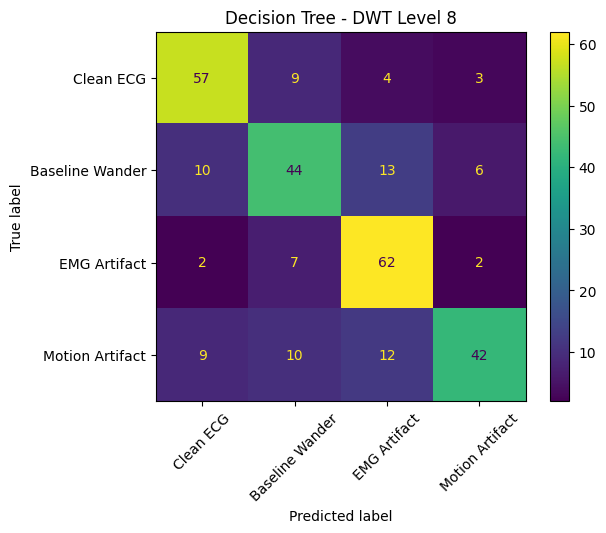

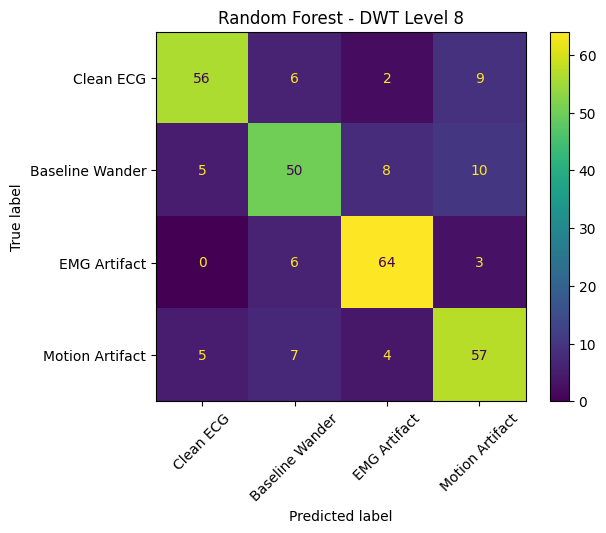

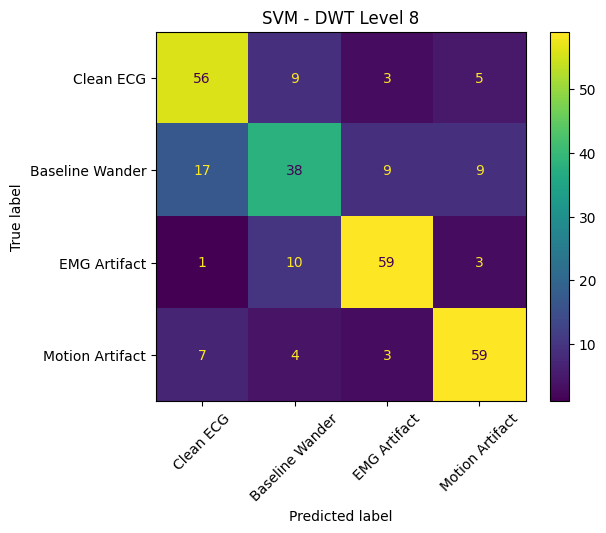

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
class_names = [
    "Clean ECG",
    "Baseline Wander",
    "EMG Artifact",
    "Motion Artifact"
]
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("Decision Tree - DWT Level 8")
plt.show()
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("Random Forest - DWT Level 8")
plt.show()
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=class_names,
    xticks_rotation=45
)
plt.title("SVM - DWT Level 8")
plt.show()

## Final Comparison

Storing without-DWT Results

In [ ]:
# Without-DWT / Conventional results
accuracy_dt_conv = 0.4452054794520548
precision_dt_conv = 0.45597845207647214
recall_dt_conv = 0.4452054794520548
f1_dt_conv = 0.44889072454620343
accuracy_rf_conv = 0.5171232876712328
precision_rf_conv = 0.5065270590110154
recall_rf_conv = 0.5171232876712328
f1_rf_conv = 0.5102550866738521
accuracy_svm_conv = 0.5582191780821918
precision_svm_conv = 0.557091932457786
recall_svm_conv = 0.5582191780821918
f1_svm_conv = 0.5568143381958248
print("Without-DWT results stored successfully.")

Without-DWT results stored successfully.


Final Performance Comparison - With DWT vs Without DWT

In [ ]:
import pandas as pd
final_comparison = pd.DataFrame({

"Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],

    "Accuracy - DWT (%)": [
        accuracy_dt * 100,
        accuracy_rf * 100,
        accuracy_svm * 100
    ],

    "Accuracy - Without DWT (%)": [
        accuracy_dt_conv * 100,
        accuracy_rf_conv * 100,
        accuracy_svm_conv * 100
    ],

    "Precision - DWT (%)": [
        precision_dt * 100,
        precision_rf * 100,
        precision_svm * 100
    ],

    "Precision - Without DWT (%)": [
        precision_dt_conv * 100,
        precision_rf_conv * 100,
        precision_svm_conv * 100
    ],

    "Recall - DWT (%)": [
        recall_dt * 100,
        recall_rf * 100,
        recall_svm * 100
    ],

    "Recall - Without DWT (%)": [
        recall_dt_conv * 100,
        recall_rf_conv * 100,
        recall_svm_conv * 100
    ],

    "F1-score - DWT (%)": [
        f1_dt * 100,
        f1_rf * 100,
        f1_svm * 100
    ],

    "F1-score - Without DWT (%)": [
        f1_dt_conv * 100,
        f1_rf_conv * 100,
        f1_svm_conv * 100
    ]
})

final_comparison.round(2)

,Model,Accuracy - DWT (%),Accuracy - Without DWT (%),Precision - DWT (%),Precision - Without DWT (%),Recall - DWT (%),Recall - Without DWT (%),F1-score - DWT (%),F1-score - Without DWT (%)
0,Decision Tree,70.21,44.52,70.83,45.60,70.21,44.52,69.83,44.89
1,Random Forest,77.74,51.71,77.88,50.65,77.74,51.71,77.69,51.03
2,SVM,72.60,55.82,72.20,55.71,72.60,55.82,72.23,55.68


Accuracy Comparison

In [ ]:
comparison_accuracy = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],
    "With DWT (%)": [
        accuracy_dt * 100,
        accuracy_rf * 100,
        accuracy_svm * 100
    ],
    "Without DWT (%)": [
        accuracy_dt_conv * 100,
        accuracy_rf_conv * 100,
        accuracy_svm_conv * 100
    ]
})
comparison_accuracy.round(2)

,Model,With DWT (%),Without DWT (%)
0,Decision Tree,70.21,44.52
1,Random Forest,77.74,51.71
2,SVM,72.60,55.82


Accuracy Improvement with DWT

In [ ]:
accuracy_improvement = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],
    "Without DWT (%)": [
        accuracy_dt_conv * 100,
        accuracy_rf_conv * 100,
        accuracy_svm_conv * 100
    ],
    "With DWT (%)": [
        accuracy_dt * 100,
        accuracy_rf * 100,
        accuracy_svm * 100
    ],
    "Improvement (percentage points)": [
        (accuracy_dt - accuracy_dt_conv) * 100,
        (accuracy_rf - accuracy_rf_conv) * 100,
        (accuracy_svm - accuracy_svm_conv) * 100
    ]
})
accuracy_improvement.round(2)

,Model,Without DWT (%),With DWT (%),Improvement (percentage points)
0,Decision Tree,44.52,70.21,25.68
1,Random Forest,51.71,77.74,26.03
2,SVM,55.82,72.60,16.78


Saving Trained DWT Models

In [ ]:
import joblib
joblib.dump(dt_model, "/content/dt_dwt_model.pkl")
joblib.dump(rf_model, "/content/rf_dwt_model.pkl")
joblib.dump(svm_model, "/content/svm_dwt_model.pkl")
print("DWT models saved successfully.")

DWT models saved successfully.
